# Conditional lighting reduction scenarios

## tl;dr
This notebook executes the scenario design from the shared workload document. It keeps modeled reductions separate from comfort validation and uses the executed tables below for the presentation summary. A zero result under the tested rules is not proof of zero physical savings potential.

The primary scenario is **strict complete-cleaned intervals, March p95 trigger, 500 lux, 20% electrical-reduction cap, 80% period coverage gate**. The original baseline remains unchanged.

## Context & Methods
**Question:** How much could zone operating-hour peak demand change under explicit lighting-reduction assumptions?

March 6–31 calibrates each zone's demand trigger; April weekday 08:00–18:00 evaluates it in Bangkok local time. The peak is recalculated across all observed April operating intervals, including no-action intervals. It is not the full-month all-hours peak.

### Key assumptions
- `lux_after = lux_before × (1 − r)` with `r = min(cap, max(0, 1 − target/lux_before))`. This is an illustrative electrical-power response, not a calibrated dimmer command or validated task-plane response.
- Lighting is the only reduced load. Recorded AC and plug demand are retained. No attendance is inferred from lux or from the scenario itself.
- Strict policy requires all 15 cleaned minutes for recorded power, and all 15 paired power/lux minutes before control eligibility. Complete cleaned readings may include interpolation.
- Common-minute sensitivity accepts >=12 common cleaned minutes; total, lighting and lux are recomputed on the same support. Its policy baseline is separate from the original baseline and strict scenario. Missing lux disables action while retaining observed power.
- Period gates of 80%/95% apply to March power and April power/paired-lux coverage. Missing sensors or inadequate evidence are withheld, not treated as proven zero potential.
- Targets [100,150,200,300,500] lux and caps [0,5,10,20]% are assumptions. Targets are not lowered to manufacture savings.

## Data
Run cleaning → original lighting baseline → `prepare_inputs.py` → assessment → this notebook. Input and implementation hashes are recorded in generated manifests. The scenario runner first reproduces all original March baseline triggers and then fits policy-specific March triggers. April cannot change calibration.

In [1]:
from pathlib import Path
import sys
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "baseline").is_dir() and (p / "data-cleaning").is_dir())
sys.path.insert(0, str(root / "analytics/lighting"))
from IPython.display import display, Markdown
from lighting_scenarios import run_scenarios, plot_scenario_results, write_combined_findings
from assessment import run_assessment
results = run_scenarios()
assessment = run_assessment()
write_combined_findings(results, assessment['opportunities'])
summary = results['summary']
sensitivity = results['sensitivity']
print(f"Executed {len(sensitivity):,} zone/scenario combinations across {len(summary)} zones.")

Executed 2,640 zone/scenario combinations across 33 zones.


## Results
### Calibration, coverage and primary outcomes
Read the status before interpreting the reduction column. Reported results are missing for insufficient evidence. Paired observed values remain available in the full CSV for calculation checks; they are not a confirmed monthly saving.

In [2]:
columns = ['floor','zone','march_p95_kW','legacy_march_p95_kW','march_coverage_pct','april_coverage_pct','april_lux_coverage_pct','status','reported_peak_reduction_kW','reported_peak_reduction_pct','reported_energy_reduction_kWh']
display(summary.loc[summary.floor.eq(2), columns].round(3))
display(summary.groupby('status').size().rename('Zones').to_frame())
qualified = summary.loc[summary.reported_peak_reduction_kW.notna()]
display(Markdown(f"**Executed primary result:** {len(qualified)} of {len(summary)} zones pass the reporting gates. Of those, {qualified.reported_peak_reduction_kW.gt(1e-9).sum()} show positive modeled peak reduction. Excluded zones remain unassessed rather than proven to have no opportunity."))

,floor,zone,march_p95_kW,legacy_march_p95_kW,march_coverage_pct,april_coverage_pct,april_lux_coverage_pct,status,reported_peak_reduction_kW,reported_peak_reduction_pct,reported_energy_reduction_kWh
339,2,1,51.726,51.726,100.0,99.659,99.432,modeled result; comfort unvalidated,0.0,0.0,0.0
419,2,2,39.710,39.710,100.0,99.659,98.750,modeled result; comfort unvalidated,0.0,0.0,0.0
499,2,3,1.639,1.639,100.0,100.000,98.409,modeled result; comfort unvalidated,0.0,0.0,0.0
579,2,4,12.533,12.533,100.0,99.659,98.295,modeled result; comfort unvalidated,0.0,0.0,0.0


,Zones
status,
insufficient calibration,5
insufficient evaluation power/lux coverage,2
modeled result; comfort unvalidated,17
no lux sensor,9


**Executed primary result:** 17 of 33 zones pass the reporting gates. Of those, 0 show positive modeled peak reduction. Excluded zones remain unassessed rather than proven to have no opportunity.

### Why the rule takes no action
These figures show binding exclusion reasons and simultaneous coverage. Overlapping before/after curves and a zero-only savings heatmap would conceal the reason for the outcome, so they are not used.

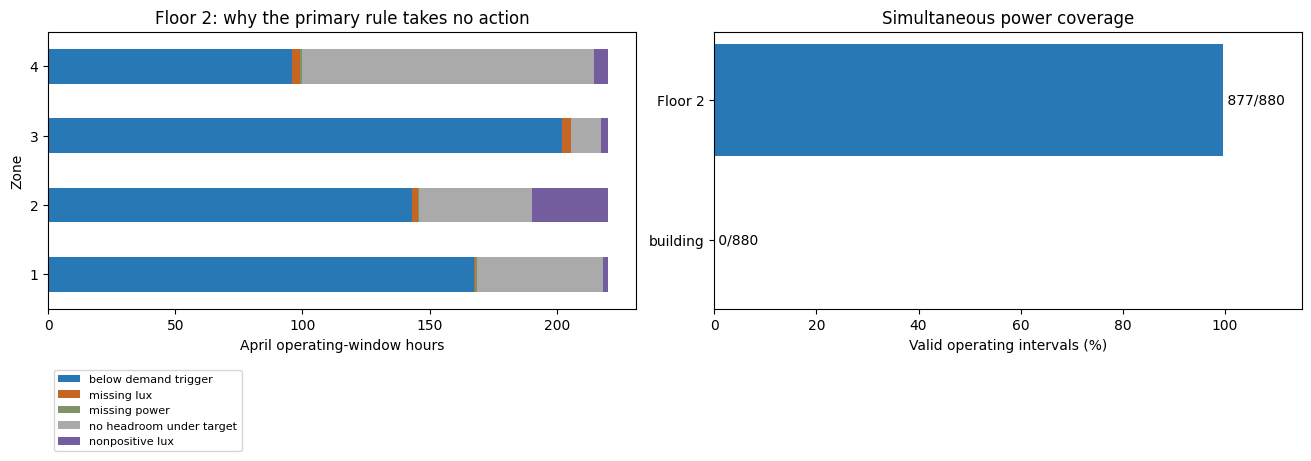

,target_lux,valid_lux_intervals,maximum_ambient_lux,intervals_at_or_above_target,status
0,100,19741,86.4,0,no observed headroom under target
1,150,19741,86.4,0,no observed headroom under target
2,200,19741,86.4,0,no observed headroom under target
3,300,19741,86.4,0,no observed headroom under target
4,500,19741,86.4,0,no observed headroom under target


In [3]:
plot_scenario_results(results)
display(results['targets'].round(3))

**Interpretation:** if the measured ambient lux is below every tested target, the lux-constrained rule cannot permit reduction even when demand exceeds March p95. That is a model/measurement outcome. It neither establishes desk-level lighting deficiency nor proves that actual lighting savings are impossible.

### Sensitivity and no-change reference
Compare gates and interval policies separately. A missing reported value is not a zero. The zero-cap cases reproduce each policy's baseline exactly; positive-cap cases recalculate the maximum over the same valid timestamps.

In [4]:
display(sensitivity.groupby(['policy','period_coverage_gate','target_lux','reduction_cap']).agg(
    reportable_zones=('reported_peak_reduction_kW','count'),
    maximum_zone_peak_reduction_kW=('reported_peak_reduction_kW','max'),
    modeled_energy_reduction_kWh=('reported_energy_reduction_kWh',lambda x:x.sum(min_count=1))).round(3))
reference = sensitivity.loc[sensitivity.reduction_cap.eq(0)]
assert reference.paired_observed_peak_reduction_kW.dropna().eq(0).all()
assert sensitivity.legacy_trigger_reproduced.all()
print('Verified: original March triggers reproduce; no-change scenarios reproduce policy baselines.')

reportable_zones  \
policy         period_coverage_gate target_lux reduction_cap                     
common_minutes 0.80                 100        0.00                         17   
                                               0.05                         17   
                                               0.10                         17   
                                               0.20                         17   
                                    150        0.00                         17   
...                                                                        ...   
strict         0.95                 300        0.20                         12   
                                    500        0.00                         12   
                                               0.05                         12   
                                               0.10                         12   
                                               0.20                         12   

                                                              maximum_zone_peak_reduction_kW  \
policy         period_coverage_gate target_lux reduction_cap                                   
common_minutes 0.80                 100        0.00                                      0.0   
                                               0.05                                      0.0   
                                               0.10                                      0.0   
                                               0.20                                      0.0   
                                    150        0.00                                      0.0   
...                                                                                      ...   
strict         0.95                 300        0.20                                      0.0   
                                    500        0.00                                      0.0   
                                               0.05                                      0.0   
                                               0.10                                      0.0   
                                               0.20                                      0.0   

                                                              modeled_energy_reduction_kWh  
policy         period_coverage_gate target_lux reduction_cap                                
common_minutes 0.80                 100        0.00                                    0.0  
                                               0.05                                    0.0  
                                               0.10                                    0.0  
                                               0.20                                    0.0  
                                    150        0.00                                    0.0  
...                                                                                    ...  
strict         0.95                 300        0.20                                    0.0  
                                    500        0.00                                    0.0  
                                               0.05                                    0.0  
                                               0.10                                    0.0  
                                               0.20                                    0.0  

[80 rows x 3 columns]

Verified: original March triggers reproduce; no-change scenarios reproduce policy baselines.


### Coincident impact
Demand is summed across aligned zones before taking a maximum. Individual zone maxima are never added. The building result is withheld if simultaneous coverage fails the gate; an aligned Floor 2 model is still not independent main-meter validation.

In [5]:
display(results['impacts'].round(3))
display(results['coverage'].round(3))

,scope,simultaneous_intervals,expected_intervals,coverage_pct,observed_baseline_peak_kW,paired_observed_peak_reduction_kW,reported_peak_reduction_kW,status
0,building,0,880,0.000,NaN,NaN,NaN,insufficient simultaneous coverage
1,Floor 2,877,880,99.659,114.824,0.0,0.0,aligned submeter scenario only; comfort/main-m...


,scope,policy,window,zones,expected_intervals,simultaneous_intervals,coverage_pct
0,building,baseline-compatible power,all hours,33,2880,24,0.833
1,building,baseline-compatible power,operating hours,33,880,0,0.000
2,building,complete cleaned power,all hours,33,2880,24,0.833
3,building,complete cleaned power,operating hours,33,880,0,0.000
4,Floor 2,baseline-compatible power,all hours,4,2880,2877,99.896
5,Floor 2,baseline-compatible power,operating hours,4,880,877,99.659
6,Floor 2,complete cleaned power,all hours,4,2880,2877,99.896
7,Floor 2,complete cleaned power,operating hours,4,880,877,99.659


## Takeaways and recommendations
- Report the executed model outcome with its target, cap, coverage gate, interval policy and operating window.
- Keep scheduling-audit exposure and occupancy-related proxies separate from a comfort-constrained dimming scenario.
- Do not lower targets to obtain a positive answer. Validate occupied task-plane light and fixture response first.
- Restore simultaneous reporting and collect independent main-meter evidence before claiming a building-wide benefit.

The combined report joins the assessment and scenario tables on `floor, zone`. It states which values are modeled, withheld or still external requirements.

In [6]:
print('Combined findings:', root / 'analytics/lighting/lighting_combined_findings.md')
print('Detailed scenario outputs:', root / 'analytics/lighting/outputs')
assert (sensitivity.paired_observed_peak_reduction_kW.dropna() >= -1e-9).all()
print('Verified: no scenario increases the observed policy peak.')

Combined findings: /Users/xiangyingg/Documents/GitHub/SBA-Final-Project/analytics/lighting/lighting_combined_findings.md
Detailed scenario outputs: /Users/xiangyingg/Documents/GitHub/SBA-Final-Project/analytics/lighting/outputs
Verified: no scenario increases the observed policy peak.


## Auditability and remaining fieldwork
See [REVISION_NOTES.md](REVISION_NOTES.md) for what was added and why, and [the README](README.md#study-scope-and-limitations) for study limitations and future validation. No site measurements, occupancy ground truth, calibrated fixture response or main-meter validation are claimed by executing this notebook.

Source: supplied [workload design](README_analytics.txt), original lighting baseline and the shared input manifest. The [thermal-comfort/glare research](https://digital.car.chula.ac.th/nakhara/vol19/iss1/6/) motivates local occupant validation; its DGP scale cannot be substituted for lux.

## Study scope and limitations

This study identifies lighting-management opportunities and evaluates conditional reduction scenarios using existing telemetry. Comfort-preserving savings and actual building-wide impact cannot be verified because task-plane measurements, occupant feedback and independent main-meter data are unavailable.

The team has no access to the building or additional measurement records. Site comfort testing and independent main-meter validation are proposed future work outside this retrospective study, rather than unfinished coding tasks.
